# Autonomous Driving Perception Stack
### Final Demonstration & Results

**Dataset:** KITTI subset  
**Core components:** Object detection · Relative depth estimation · Multi-object tracking · Experimental lane detection

---

## Executive Summary

This notebook brings together the project's final outputs, quantitative evaluation, and known limitations. It demonstrates a YOLO-based road-object detector, monocular **relative** depth estimation, ByteTrack tracking on a road video, and a classical OpenCV lane-detection baseline.

> **Scope note:** This is an educational prototype, not a production-ready or safety-certified autonomous-driving system. Depth values are relative rather than distances in metres, and lane detection remains experimental.

## Contents

1. [Project setup](#1-project-setup)
2. [Object detection: evaluation results](#2-object-detection-results)
3. [Integrated image demo: detection and relative depth](#3-integrated-image-demo)
4. [Object tracking](#4-object-tracking)
5. [Lane detection](#5-lane-detection)
6. [Performance benchmark](#6-performance-benchmark)
7. [Limitations and future work](#7-limitations-and-future-work)
8. [Conclusion](#8-conclusion)

In [5]:
from pathlib import Path
import pandas as pd
import numpy as np
import cv2
import matplotlib.pyplot as plt
from IPython.display import display, Video, Image as IPyImage
from ultralytics import YOLO

# Find the project root whether this notebook is opened from the project
# directory or from its notebook/ subdirectory.
cwd = Path.cwd()
candidates = [cwd, cwd.parent, *cwd.parents]
project_dir = next(
    (p for p in candidates if (p / "data" / "kitti.yaml").exists()),
    None
)

if project_dir is None:
    raise FileNotFoundError(
        "Could not find the project root. Expected data/kitti.yaml "
        "in the current directory or one of its parent directories."
    )

model_path = project_dir / "runs" / "kitti_improved" / "weights" / "best.pt"
data_yaml = project_dir / "data" / "kitti.yaml"
benchmark_path = project_dir / "runs" / "benchmarking" / "yolo_benchmark.csv"
output_dir = project_dir / "runs" / "final_demo"

print("Project root:", project_dir)
print("Detector checkpoint exists:", model_path.exists())
print("Dataset configuration exists:", data_yaml.exists())
print("Benchmark file exists:", benchmark_path.exists())

if not model_path.exists():
    raise FileNotFoundError(f"Missing trained model: {model_path}")

model = YOLO(str(model_path))
output_dir.mkdir(parents=True, exist_ok=True)

Project root: c:\Users\yatha\Desktop\autonomous-driving-perception
Detector checkpoint exists: True
Dataset configuration exists: True
Benchmark file exists: True


## 1. Project Setup

The notebook locates the project root automatically and loads the trained YOLO checkpoint. The expected project artifacts are:

- `runs/kitti_improved/weights/best.pt` - trained object detector
- `data/kitti.yaml` - dataset configuration
- `runs/benchmarking/yolo_benchmark.csv` - YOLO benchmark measurements
- `runs/tracking/road_clip_bytetrack/` - tracking video output
- `runs/final_demo/` - saved visual results

If an optional output is missing, the relevant section reports that it could not be found.

## 2. Object Detection Results

The YOLO11n detector was fine-tuned on a subset of KITTI. The dataset subset contains **199 training images** and **200 validation images**, with **8 labeled classes**.

| Metric | Validation result |
|---|---:|
| Precision | 42.5% |
| Recall | 32.3% |
| mAP@50 | 33.2% |
| mAP@50–95 | 18.4% |

The best checkpoint was recorded at epoch 37 in a training run configured for up to 50 epochs with early stopping. Performance was strongest for cars; less frequent classes were more difficult.

**Interpretation:** These results provide a baseline for this small dataset subset and should not be interpreted as performance on all road conditions.

## 3. Integrated Image Demo

This section runs the trained detector and Intel DPT Hybrid depth model on one validation image. The three outputs are shown separately for readability and saved under `runs/final_demo/`.

- **Object detection:** bounding boxes and class labels from YOLO.
- **Relative depth:** a normalized visualization of monocular depth predictions.
- **Important:** the depth map is not metric depth and does not report distance in metres.

Inference device: cuda


Loading weights:   0%|          | 0/414 [00:00<?, ?it/s]

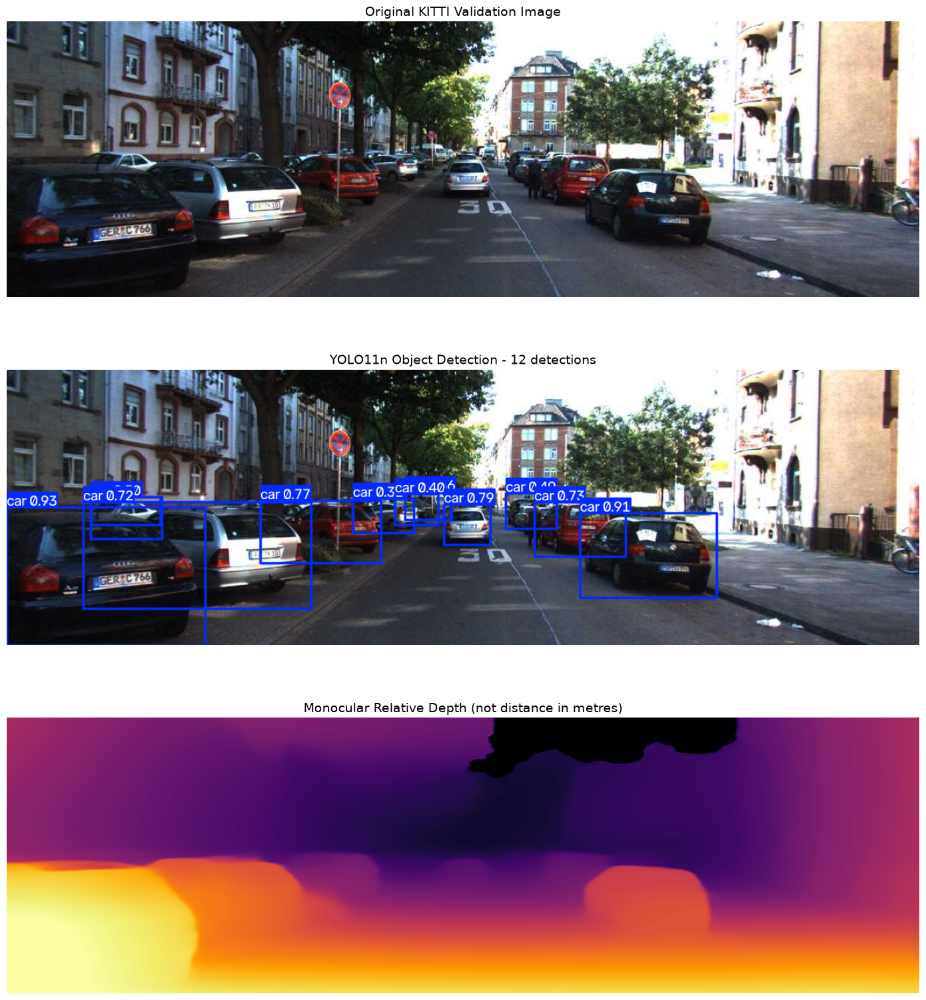

Detected objects: 12
Saved image outputs to: c:\Users\yatha\Desktop\autonomous-driving-perception\runs\final_demo


In [6]:
import torch
from PIL import Image
from transformers import DPTImageProcessor, DPTForDepthEstimation

val_dir = project_dir / "data" / "kitti_yolo" / "images" / "val"
image_path = val_dir / "007393.jpg"

if not image_path.exists():
    raise FileNotFoundError(
        f"Demo image not found: {image_path}. "
        "Update image_path to a filename available in the validation folder."
    )

image_bgr = cv2.imread(str(image_path))
if image_bgr is None:
    raise ValueError(f"OpenCV could not read image: {image_path}")

image_rgb = cv2.cvtColor(image_bgr, cv2.COLOR_BGR2RGB)
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Inference device:", device)

# Object detection
detection = model.predict(
    source=image_bgr,
    imgsz=416,
    conf=0.25,
    device=0 if device.type == "cuda" else "cpu",
    verbose=False
)[0]
annotated_rgb = cv2.cvtColor(detection.plot(), cv2.COLOR_BGR2RGB)

# Monocular relative depth estimation
depth_name = "Intel/dpt-hybrid-midas"
processor = DPTImageProcessor.from_pretrained(depth_name)
depth_model = DPTForDepthEstimation.from_pretrained(depth_name).to(device).eval()

inputs = processor(images=Image.fromarray(image_rgb), return_tensors="pt")
inputs = {key: value.to(device) for key, value in inputs.items()}

with torch.no_grad():
    depth_output = depth_model(**inputs).predicted_depth

depth_raw = torch.nn.functional.interpolate(
    depth_output.unsqueeze(1),
    size=image_rgb.shape[:2],
    mode="bicubic",
    align_corners=False
).squeeze().cpu().numpy()

low, high = np.percentile(depth_raw, [2, 98])
depth_visual = np.clip((depth_raw - low) / (high - low + 1e-8), 0, 1)

# Save outputs
cv2.imwrite(str(output_dir / "original.jpg"), cv2.cvtColor(image_rgb, cv2.COLOR_RGB2BGR))
cv2.imwrite(str(output_dir / "object_detection.jpg"), cv2.cvtColor(annotated_rgb, cv2.COLOR_RGB2BGR))
plt.imsave(str(output_dir / "relative_depth.png"), depth_visual, cmap="inferno")

# Display the three outputs vertically
fig, axes = plt.subplots(3, 1, figsize=(14, 16))
axes[0].imshow(image_rgb)
axes[0].set_title("Original KITTI Validation Image", fontsize=14)
axes[1].imshow(annotated_rgb)
axes[1].set_title(f"YOLO11n Object Detection - {len(detection.boxes)} detections", fontsize=14)
axes[2].imshow(depth_visual, cmap="inferno")
axes[2].set_title("Monocular Relative Depth (not distance in metres)", fontsize=14)

for ax in axes:
    ax.axis("off")

plt.tight_layout()
plt.show()

print(f"Detected objects: {len(detection.boxes)}")
print("Saved image outputs to:", output_dir)

## 4. Object Tracking

ByteTrack was used with the trained YOLO detector to associate detections across consecutive frames in a road video. The annotated output should show bounding boxes and track IDs.

Track IDs represent associations made by the tracker; the number of distinct IDs observed is **not** necessarily the number of physical objects in the scene.

In [3]:
tracking_dir = project_dir / "runs" / "tracking" / "road_clip_bytetrack"

if not tracking_dir.exists():
    print("Tracking output folder not found:", tracking_dir)
    print("Run notebook 03_object_tracking.ipynb first.")
else:
    video_files = [
        path for path in tracking_dir.iterdir()
        if path.is_file() and path.suffix.lower() in {".mp4", ".avi", ".mov", ".mkv"}
    ]

    if video_files:
        tracked_video = max(video_files, key=lambda path: path.stat().st_size)
        print("Tracking video:", tracked_video.name)
        display(Video(filename=str(tracked_video), embed=True, width=900))
    else:
        print("No rendered video found in:", tracking_dir)
        print("Files available:", [path.name for path in tracking_dir.iterdir()])

Tracking video: istockphoto-531954524-640_adpp_is.avi


## 5. Lane Detection

A classical OpenCV baseline was implemented using Gaussian blur, Canny edge detection, a road-region mask, and Hough line detection. The result below is loaded from `runs/final_demo/lane_detection.png`, generated in `04_lane_detection.ipynb`.

**Known limitation:** this approach can mistake road edges, shadows, parked vehicles, and other high-contrast lines for lane boundaries. Treat the visualization as an experimental baseline rather than reliable lane perception.

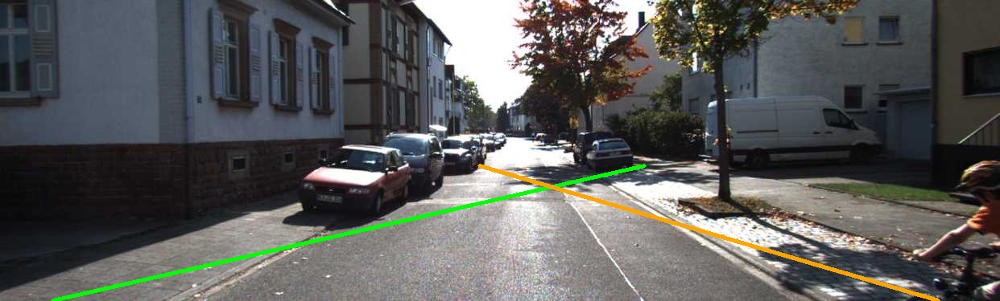

In [4]:
lane_output_path = output_dir / "lane_detection.png"

if lane_output_path.exists():
    display(IPyImage(filename=str(lane_output_path), width=1000))
else:
    print("Lane-detection output not found:", lane_output_path)
    print("Run notebook 04_lane_detection.ipynb and save its output to this path.")

## 6. Performance Benchmark

The detector was benchmarked on **50 validation images** using an NVIDIA GeForce GTX 1650 (4 GB VRAM).

| Measurement | Result |
|---|---:|
| Mean latency | 29.11 ms/image |
| Median latency | 25.26 ms/image |
| 95th-percentile latency | 44.05 ms/image |
| Approximate throughput | 34.35 images/second |
| Mean detections per image | 4.52 |

These values describe the **YOLO-only benchmark**. They do not represent end-to-end throughput for the combined detection, depth-estimation, tracking, and lane-detection stack.

In [5]:
# Load the recorded benchmark, when available, and display a compact summary.
if benchmark_path.exists():
    benchmark_df = pd.read_csv(benchmark_path)
    display(benchmark_df.head())

    if "latency_ms" in benchmark_df.columns:
        latency = pd.to_numeric(benchmark_df["latency_ms"], errors="coerce").dropna()
        if not latency.empty:
            summary = pd.DataFrame({
                "Measurement": [
                    "Valid benchmark samples",
                    "Mean latency (ms/image)",
                    "Median latency (ms/image)",
                    "95th percentile (ms/image)",
                    "Approximate throughput (images/second)"
                ],
                "Value": [
                    len(latency),
                    round(latency.mean(), 2),
                    round(latency.median(), 2),
                    round(latency.quantile(0.95), 2),
                    round(1000 / latency.mean(), 2) if latency.mean() > 0 else np.nan
                ]
            })
            display(summary)
else:
    print("Benchmark CSV not found:", benchmark_path)

,image,latency_ms,detections
0,000098.jpg,120.7088,7
1,000123.jpg,24.8478,1
2,000169.jpg,28.0582,17
3,000172.jpg,53.0758,6
4,000195.jpg,67.8395,1


,Measurement,Value
0,Valid benchmark samples,50.00
1,Mean latency (ms/image),29.11
2,Median latency (ms/image),25.26
3,95th percentile (ms/image),44.05
4,Approximate throughput (images/second),34.35


## 7. Limitations and Future Work

### Current limitations

- **Dataset size:** training and validation use a small KITTI subset, so results may not generalize to varied weather, lighting, road layouts, or traffic conditions.
- **Class imbalance:** rare classes have fewer examples and are harder to detect reliably.
- **Relative depth:** the DPT output is a relative depth visualization, not calibrated distance in metres.
- **Lane detection:** the Hough-line baseline is sensitive to shadows, road edges, and missing or faded markings.
- **Evaluation scope:** the reported benchmark measures YOLO inference only; the complete stack has not been benchmarked end to end.
- **Safety:** the prototype is not validated for real-world vehicle control or safety-critical use.

### Future improvements

1. Train and validate on a larger, more representative dataset.
2. Improve class balance and report per-class metrics.
3. Evaluate a lane-specific segmentation model on labeled lane data.
4. Compare depth predictions against calibrated ground-truth distances.
5. Measure end-to-end latency and memory use for the integrated pipeline.
6. Add tests for failure cases and evaluate performance across different scenes.

## 8. Conclusion

This project demonstrates a prototype road-scene perception workflow combining YOLO11n object detection, monocular relative depth estimation, ByteTrack multi-object tracking, and an experimental OpenCV lane-detection baseline.

On the selected KITTI subset, the detector achieved **33.2% mAP@50**. The recorded YOLO-only benchmark reported **29.11 ms mean latency** and approximately **34.35 images/second** on an NVIDIA GTX 1650. These figures apply to the object detector benchmark, not the full integrated system.

The project establishes a useful baseline for further work in dataset scale, model accuracy, lane-specific perception, depth calibration, and end-to-end performance evaluation.

